# Camada Preventiva de Priorização Territorial (Conecta Recife)
## Sprints 1 e 2: preparação dos dados (Entrega 2 do plano)

Este notebook roda no **Google Colab** e também localmente (VS Code). Ele executa as 11 etapas de limpeza do plano, registra as perdas em cada etapa e salva as bases tratadas.

**Como usar:** rode as células em ordem (*Ambiente de execução → Executar tudo*). Há uma pausa manual na etapa 4 (classificar `SITUACAO`) e na etapa 10 (decodificar `TIPO` da drenagem); as células avisam o que fazer.

**Arquivos esperados em `dados/bruto/`:** `156_2023.csv`, `156_2024.csv`, `156_2025.csv`, `bairros.geojson`, `drenagem_elementos.geojson`, `drenagem_rede.geojson`, `setores_coleta.geojson`, `roteiro_coleta.csv`, `onde_descartar.csv` e, opcionalmente, `defesa_civil_2023.csv`, `defesa_civil_2024.csv`, `defesa_civil_2025.csv`.

# Sprint 1: ambiente, caminhos e conferência dos dados

In [2]:
# ===== AMBIENTE E CAMINHOS =====
%pip install -q geopandas pyarrow

import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    EM_COLAB = True
    # ajuste se a sua pasta no Drive tiver outro nome
    PASTA = '/content/drive/MyDrive/projetos5-scope/camada_preventiva'
except ImportError:
    EM_COLAB = False
    # fora do Colab (VS Code): sobe a partir da pasta atual até achar a pasta que contém 'dados'
    # (assim funciona mesmo com o notebook dentro de notebooks/). Ou use a variável PASTA_LOCAL.
    PASTA = os.environ.get('PASTA_LOCAL')
    if not PASTA:
        PASTA = os.path.abspath(os.getcwd())
        while not os.path.isdir(os.path.join(PASTA, 'dados')) and PASTA != os.path.dirname(PASTA):
            PASTA = os.path.dirname(PASTA)

# Opcional: aponte para outra pasta de dados brutos (ex.: Google Drive para computador). None = padrão.
BRUTO_CUSTOM = None   # ex.: r'G:\Meu Drive\NOME_DA_PASTA\dados\bruto'

BRUTO  = BRUTO_CUSTOM or f'{PASTA}/dados/bruto'
PROC   = f'{PASTA}/dados/processado'
SAIDAS = f'{PASTA}/saidas'
# NÃO cria dados/bruto sozinho: se ela não existir, avisa o que há na pasta e o que fazer
if not os.path.isdir(BRUTO):
    dados = os.path.join(PASTA, 'dados')
    msg = f'Não achei a pasta {BRUTO}\n'
    msg += f'Conteúdo de {PASTA}: {sorted(os.listdir(PASTA)) if os.path.isdir(PASTA) else "(não existe)"}\n'
    if os.path.isdir(dados):
        msg += f'Conteúdo de {dados}: {sorted(os.listdir(dados))}\n'
    if EM_COLAB:
        msg += ('Colab: confira PASTA. Se o projeto está em "Compartilhados comigo", adicione um atalho dele '
                'ao Meu Drive (com outro nome) e use o caminho do atalho.')
    else:
        msg += ('VS Code: crie a pasta dados/bruto dentro de camada_preventiva e coloque nela os arquivos brutos '
                '(156_2023.csv, 156_2024.csv, 156_2025.csv, bairros.geojson, drenagem_elementos.geojson, ...).')
    raise FileNotFoundError(msg)
for p in (PROC, SAIDAS):
    os.makedirs(p, exist_ok=True)

# ===== PARÂMETROS DO PROJETO (calibre aqui) =====
ANOS = [2023, 2024, 2025]
GRUPOS_RECORTE = ['LIMPEZA URBANA', 'DRENAGEM']   # termos buscados em GRUPOSERVICO_DESCRICAO
RPA_PILOTO = None                                 # ex.: 3 para recortar uma RPA; None = cidade toda
AREA_MIN_M2 = 500                                 # etapa 9: partes de setor menores que isso são removidas
CRS_M = 'EPSG:31985'                              # SIRGAS 2000 / UTM 25S (metros)

print('Pasta do projeto:', PASTA)
arquivos = sorted(os.listdir(BRUTO))
print(arquivos)
if not arquivos:
    print('\nATENÇÃO: a pasta dados/bruto está VAZIA. Os arquivos não estão neste caminho.')
    print('Se a pasta do projeto está em "Compartilhados comigo", adicione um atalho dela ao Meu Drive')
    print('e ajuste PASTA. Depois rode: drive.mount("/content/drive", force_remount=True)')

Note: you may need to restart the kernel to use updated packages.
Pasta do projeto: c:\Users\brend\OneDrive\Documentos\projetos5-scope\camada_preventiva
['156_2023.csv', '156_2024.csv', '156_2025.csv', 'bairros.geojson', 'defesa_civil_2023.csv', 'defesa_civil_2024.csv', 'defesa_civil_2025.csv', 'drenagem_elementos.geojson', 'drenagem_rede.geojson', 'onde_descartar.csv', 'roteiros_coleta.csv', 'setores_coleta.geojson']


In [3]:
# ===== FUNÇÕES AUXILIARES =====
import re, unicodedata
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display

def sem_acento(s):
    return ''.join(c for c in unicodedata.normalize('NFKD', str(s)) if not unicodedata.combining(c))

def norm_texto(s):
    # MAIÚSCULO, sem acento, sem espaços repetidos
    if pd.isna(s):
        return s
    return re.sub(r'\s+', ' ', sem_acento(s).upper().strip())

def norm_coluna(c):
    return re.sub(r'\W+', '_', norm_texto(c)).strip('_')

ABREV = {r'\bAV\b': 'AVENIDA', r'\bR\b': 'RUA', r'\bTV\b': 'TRAVESSA', r'\bPC\b': 'PRACA',
         r'\bEST\b': 'ESTRADA', r'\bAL\b': 'ALAMEDA', r'\bLG\b': 'LARGO', r'\bDR\b': 'DOUTOR',
         r'\bPROF\b': 'PROFESSOR', r'\bCEL\b': 'CORONEL', r'\bSTA\b': 'SANTA', r'\bSTO\b': 'SANTO',
         r'\b1TR\b': 'PRIMEIRA TRAVESSA', r'\b2TR\b': 'SEGUNDA TRAVESSA', r'\b3TR\b': 'TERCEIRA TRAVESSA'}

def expandir_abrev(s):
    if pd.isna(s):
        return s
    for pat, rep in ABREV.items():
        s = re.sub(pat, rep, s)
    return s

def ler_csv(caminho):
    # tenta combinações de encoding e separador e diz o motivo real se falhar
    if not os.path.exists(caminho):
        pasta = os.path.dirname(caminho)
        existe = sorted(os.listdir(pasta)) if os.path.isdir(pasta) else 'a pasta nem existe'
        raise FileNotFoundError(f'Arquivo não encontrado: {caminho}\nConteúdo da pasta: {existe}')
    ultimo = None
    for enc in ('utf-8', 'utf-8-sig', 'latin-1'):
        for sep in (';', ','):
            try:
                d = pd.read_csv(caminho, sep=sep, encoding=enc, dtype=str, low_memory=False)
                if d.shape[1] > 1:
                    return d
            except Exception as e:
                ultimo = e
    raise ValueError(f'O arquivo existe, mas não consegui ler: {caminho}\nÚltimo erro: {ultimo}')

def parse_data(s):
    s = s.astype('string').str.strip()
    iso = s.str.match(r'^\d{4}-\d{2}-\d{2}', na=False)
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    out[iso] = pd.to_datetime(s[iso].str[:10], format='%Y-%m-%d', errors='coerce')
    out[~iso] = pd.to_datetime(s[~iso].str[:10], format='%d/%m/%Y', errors='coerce')
    return out

def achar_coluna(df, *candidatas):
    for c in candidatas:
        if c in df.columns:
            return c
    raise KeyError(f'Nenhuma destas colunas existe: {candidatas}. Colunas disponíveis: {list(df.columns)}')

def para_numero(s):
    return pd.to_numeric(s.astype('string').str.replace(',', '.', regex=False), errors='coerce')

# tabela de perdas: registra quantas linhas entram e saem em cada etapa
perdas = []
def log(etapa, antes, depois, obs=''):
    perdas.append({'etapa': etapa, 'entrou': antes, 'saiu': depois, 'perdeu': antes - depois, 'obs': obs})
    print(f'[{etapa}] {antes:,} -> {depois:,} (perdeu {antes - depois:,}) {obs}')

In [4]:
# ===== CONFERÊNCIA DOS ARQUIVOS BRUTOS =====
for nome in sorted(os.listdir(BRUTO)):
    caminho = f'{BRUTO}/{nome}'
    mb = os.path.getsize(caminho) / 1e6
    try:
        if nome.endswith('.geojson'):
            g = gpd.read_file(caminho)
            print(f'OK   {nome:34} {mb:7.1f} MB  {len(g):>9,} feições  CRS={g.crs}')
        elif nome.endswith('.csv'):
            d = ler_csv(caminho)
            print(f'OK   {nome:34} {mb:7.1f} MB  {len(d):>9,} linhas  {d.shape[1]} colunas')
        else:
            print(f'??   {nome:34} {mb:7.1f} MB  extensão não reconhecida')
    except Exception as e:
        print(f'ERRO {nome:34} {mb:7.1f} MB  {e}')

OK   156_2023.csv                          25.4 MB     93,555 linhas  13 colunas
OK   156_2024.csv                          18.6 MB    108,082 linhas  13 colunas
OK   156_2025.csv                          14.8 MB     86,966 linhas  13 colunas
OK   bairros.geojson                        2.2 MB         94 feições  CRS=EPSG:4326
OK   defesa_civil_2023.csv                 13.8 MB     83,164 linhas  16 colunas
OK   defesa_civil_2024.csv                 13.1 MB     80,173 linhas  16 colunas
OK   defesa_civil_2025.csv                  0.0 MB          1 linhas  16 colunas
OK   drenagem_elementos.geojson            62.1 MB     75,911 feições  CRS=EPSG:4326
OK   drenagem_rede.geojson                 28.1 MB     73,538 feições  CRS=EPSG:4326
OK   onde_descartar.csv                     0.0 MB         79 linhas  13 colunas
OK   roteiros_coleta.csv                    0.4 MB      5,046 linhas  6 colunas
OK   setores_coleta.geojson                 3.2 MB        922 feições  CRS=EPSG:4326


# Sprint 2: limpeza e normalização do 156 (etapas 1 a 7)

In [5]:
# ===== ETAPA 0: juntar 2023, 2024 e 2025 =====
partes = []
for ano in ANOS:
    d = ler_csv(f'{BRUTO}/156_{ano}.csv')
    d.columns = [norm_coluna(c) for c in d.columns]
    d['ANO_ARQUIVO'] = ano
    print(ano, d.shape)
    partes.append(d)

comuns = set.intersection(*[set(p.columns) for p in partes])
todas = set.union(*[set(p.columns) for p in partes])
if todas - comuns:
    print('ATENÇÃO: colunas que não existem em todos os anos:', sorted(todas - comuns))

df = pd.concat(partes, ignore_index=True)
log('0 juntar 2023-2025', len(df), len(df))
print(df.columns.tolist())

# grupos de serviço existentes: confira se os termos de GRUPOS_RECORTE batem
df['_GRUPO'] = df[achar_coluna(df, 'GRUPOSERVICO_DESCRICAO')].map(norm_texto)
grupos = df['_GRUPO'].value_counts().rename_axis('grupo').reset_index(name='n')
grupos.to_csv(f'{SAIDAS}/grupos_servico.csv', index=False)
display(grupos.head(20))

2023 (93555, 14)
2024 (108082, 14)
2025 (86966, 14)
[0 juntar 2023-2025] 288,603 -> 288,603 (perdeu 0) 
['GRUPOSERVICO_CODIGO', 'GRUPOSERVICO_DESCRICAO', 'SERVICO_CODIGO', 'SERVICO_DESCRICAO', 'LOGRADOURO', 'NUMERO', 'BAIRRO', 'RPA', 'DATA_DEMANDA', 'SITUACAO', 'DATA_ULT_SITUACAO', 'LATITUDE', 'LONGITUDE', 'ANO_ARQUIVO']


,grupo,n
0,ILUMINACAO PUBLICA,80778
1,LIMPEZA URBANA,51858
2,DRENAGEM,35979
3,ILUMINAO PBLICA,35178
4,ARBORIZACAO,20883
5,ARBORIZAO,12076
6,PAVIMENTACAO,8814
7,PAVIMENTAO,5666
8,ESCADARIA,5306
9,DENUNCIAS,5231


In [6]:
# ===== ETAPAS 1 e 2: filtrar o recorte e remover duplicatas =====
n = len(df)
df = df[df['_GRUPO'].fillna('').apply(lambda g: any(t in g for t in GRUPOS_RECORTE))].copy()
log('1 filtrar recorte', n, len(df), f'termos={GRUPOS_RECORTE}')
if df.empty:
    raise ValueError('O filtro zerou a base: ajuste GRUPOS_RECORTE com base na tabela de grupos acima.')

n = len(df)
df = df.drop_duplicates()
log('2 duplicatas exatas', n, len(df))

[1 filtrar recorte] 288,603 -> 91,140 (perdeu 197,463) termos=['LIMPEZA URBANA', 'DRENAGEM']
[2 duplicatas exatas] 91,140 -> 91,140 (perdeu 0) 


In [7]:
# ===== ETAPA 3: converter datas e descartar as fora do ano do arquivo =====
df['DATA_DEMANDA'] = parse_data(df[achar_coluna(df, 'DATA_DEMANDA')])
df['DATA_ULT_SITUACAO'] = parse_data(df[achar_coluna(df, 'DATA_ULT_SITUACAO', 'DATA_ULTIMA_SITUACAO')])

n = len(df)
df = df[df['DATA_DEMANDA'].dt.year == df['ANO_ARQUIVO']].copy()
log('3 datas inválidas ou fora do ano', n, len(df))

[3 datas inválidas ou fora do ano] 91,140 -> 79,189 (perdeu 11,951) 


In [8]:
# ===== ETAPA 4: classificar SITUACAO em FINAL ou ABERTA =====
df['SITUACAO'] = df[achar_coluna(df, 'SITUACAO')].map(norm_texto)

arq_sit = f'{SAIDAS}/situacoes_unicas.csv'
sit = df['SITUACAO'].value_counts().rename_axis('situacao').reset_index(name='n')
if os.path.exists(arq_sit):
    # preserva a classificação que você já preencheu
    antigo = pd.read_csv(arq_sit, dtype=str)[['situacao', 'tipo']]
    sit = sit.merge(antigo, on='situacao', how='left')
else:
    sit['tipo'] = ''
sit['tipo'] = sit['tipo'].fillna('')
sit.to_csv(arq_sit, index=False)
display(sit)

mapa_sit = dict(zip(sit['situacao'], sit['tipo'].str.upper().str.strip()))
df['SITUACAO_TIPO'] = df['SITUACAO'].map(mapa_sit).replace('', pd.NA)
pendentes = int(df['SITUACAO_TIPO'].isna().sum())
if pendentes:
    print(f'PAUSA MANUAL: preencha a coluna "tipo" (FINAL ou ABERTA) em {arq_sit}, '
          f'depois rode esta célula de novo. Linhas sem classificação: {pendentes:,}')
else:
    print('Todas as situações estão classificadas.')
log('4 classificar SITUACAO', len(df), len(df), f'{pendentes:,} linhas ainda sem classificação (FINAL/ABERTA)')

,situacao,n,tipo
0,ATENDIDA,50373,
1,CADASTRADA,22677,
2,EXECUCAO,3784,
3,PREPARAO,966,
4,PREPARACAO,675,
5,PENDENCIA,307,
6,PENDENTE,162,
7,FISCALIZAO,135,
8,EXECUO,55,
9,FISCALIZACAO,55,


PAUSA MANUAL: preencha a coluna "tipo" (FINAL ou ABERTA) em c:\Users\brend\OneDrive\Documentos\projetos5-scope\camada_preventiva/saidas/situacoes_unicas.csv, depois rode esta célula de novo. Linhas sem classificação: 79,189
[4 classificar SITUACAO] 79,189 -> 79,189 (perdeu 0) 79,189 linhas ainda sem classificação (FINAL/ABERTA)


In [9]:
# ===== ETAPAS 5 e 6: validar coordenadas e tratar as faltantes =====
df['LAT'] = para_numero(df[achar_coluna(df, 'LATITUDE', 'LAT')])
df['LON'] = para_numero(df[achar_coluna(df, 'LONGITUDE', 'LON', 'LONG')])
sem_coord = df[['LAT', 'LON']].isna().any(axis=1)

# limite real do Recife = união dos bairros
bairros = gpd.read_file(f'{BRUTO}/bairros.geojson')
if bairros.crs is None:
    bairros = bairros.set_crs(4326)
bairros = bairros.to_crs(4326)
limite = bairros.union_all() if hasattr(bairros, 'union_all') else bairros.unary_union

ok = ~sem_coord
pts = gpd.GeoSeries(gpd.points_from_xy(df.loc[ok, 'LON'], df.loc[ok, 'LAT']), crs=4326, index=df.index[ok])
dentro = pts.within(limite)

df['COORD_VALIDA'] = False
df.loc[dentro[dentro].index, 'COORD_VALIDA'] = True

# etapa 5: ponto fora do Recife não entra na análise por ponto (a linha é mantida e marcada)
log('5 validar coordenadas (limite do Recife)', int(ok.sum()), int(df['COORD_VALIDA'].sum()),
    'fora do limite: linhas mantidas, marcadas COORD_VALIDA=False')
# etapa 6: sem coordenada fica fora da análise por ponto, mas continua nas contagens por bairro
log('6 coordenadas faltantes', len(df), int(ok.sum()),
    'sem coordenada: mantidas para contagens por bairro, excluídas da análise por ponto')
print(f'Com coordenada válida: {df["COORD_VALIDA"].mean() * 100:.1f}% das linhas')

[5 validar coordenadas (limite do Recife)] 41,528 -> 41,186 (perdeu 342) fora do limite: linhas mantidas, marcadas COORD_VALIDA=False
[6 coordenadas faltantes] 79,189 -> 41,528 (perdeu 37,661) sem coordenada: mantidas para contagens por bairro, excluídas da análise por ponto
Com coordenada válida: 52.0% das linhas


In [10]:
# ===== ETAPA 7: padronizar texto (BAIRRO, LOGRADOURO, NUMERO) =====
for c in ('BAIRRO', 'LOGRADOURO'):
    if c in df.columns:
        df[c] = df[c].map(norm_texto).map(expandir_abrev)
if 'NUMERO' in df.columns:
    df['NUMERO'] = df['NUMERO'].map(norm_texto).replace({'SN': pd.NA, 'S/N': pd.NA})

if 'RPA' in df.columns:
    df['RPA_NUM'] = pd.to_numeric(df['RPA'].astype('string').str.extract(r'(\d+)')[0], errors='coerce')
    if RPA_PILOTO is not None:
        n = len(df)
        df = df[df['RPA_NUM'] == RPA_PILOTO].copy()
        log(f'7b recorte RPA {RPA_PILOTO}', n, len(df))

df = df.drop(columns=['_GRUPO']).reset_index(drop=True)
df.insert(0, 'ID_LINHA', np.arange(len(df)))
log('7 padronizar texto', len(df), len(df), 'BAIRRO, LOGRADOURO e NUMERO')
df.head()

[7 padronizar texto] 79,189 -> 79,189 (perdeu 0) BAIRRO, LOGRADOURO e NUMERO


,ID_LINHA,GRUPOSERVICO_CODIGO,GRUPOSERVICO_DESCRICAO,SERVICO_CODIGO,SERVICO_DESCRICAO,LOGRADOURO,NUMERO,BAIRRO,RPA,DATA_DEMANDA,SITUACAO,DATA_ULT_SITUACAO,LATITUDE,LONGITUDE,ANO_ARQUIVO,SITUACAO_TIPO,LAT,LON,COORD_VALIDA,RPA_NUM
0,0,11,DRENAGEM,97,RECUP.DE CANALETAS DE DRENAGEM ...,1SB CORREGO DA LOURA,,BREJO DA GUABIRABA,3,2023-05-16,CADASTRADA,2023-05-16,-7.9961436,-34.9362847,2023,NaN,-7.996144,-34.936285,True,3
1,1,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1SB CORREGO DO LEONCIO,,NOVA DESCOBERTA,3,2023-06-01,ATENDIDA,2023-07-27,-8.0028869,-34.9274109,2023,NaN,-8.002887,-34.927411,True,3
2,2,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1SB BARAO CAMAQUA,,NOVA DESCOBERTA,3,2023-03-09,ATENDIDA,2023-04-27,-8.0059289,-34.9229936,2023,NaN,-8.005929,-34.922994,True,3
3,3,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1SB BARAO CAMAQUA,,NOVA DESCOBERTA,3,2023-09-13,ATENDIDA,2023-12-11,-8.0059289,-34.9229936,2023,NaN,-8.005929,-34.922994,True,3
4,4,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,PRIMEIRA TRAVESSA AGUIA BRANCA,,NOVA DESCOBERTA,3,2023-03-04,ATENDIDA,2023-04-05,-8.0032816,-34.9281972,2023,NaN,-8.003282,-34.928197,True,3


# Sprint 2: bases de apoio (etapas 8 a 11)

In [11]:
# ===== ETAPA 8: projetar tudo para SIRGAS 2000 / UTM 25S (EPSG:31985) =====
v = df[df['COORD_VALIDA']]
g = gpd.GeoDataFrame(v[[]], geometry=gpd.points_from_xy(v['LON'], v['LAT']), crs=4326).to_crs(CRS_M)
df['X'] = g.geometry.x
df['Y'] = g.geometry.y

def abrir(nome):
    x = gpd.read_file(f'{BRUTO}/{nome}')
    if x.crs is None:
        x = x.set_crs(4326)
    x.columns = [c if c == 'geometry' else norm_coluna(c) for c in x.columns]
    return x.to_crs(CRS_M)

elementos = abrir('drenagem_elementos.geojson')
rede = abrir('drenagem_rede.geojson')
setores = abrir('setores_coleta.geojson')
bairros_m = bairros.to_crs(CRS_M)

log('8 projetar para EPSG:31985', len(df), len(df),
    f'denúncias, {len(elementos):,} elementos, {len(rede):,} trechos, {len(setores):,} setores, {len(bairros_m):,} bairros')
print('Colunas dos setores:', setores.columns.tolist())
print('Colunas dos elementos:', elementos.columns.tolist())
print('Colunas da rede:', rede.columns.tolist())

[8 projetar para EPSG:31985] 79,189 -> 79,189 (perdeu 0) denúncias, 75,911 elementos, 73,538 trechos, 922 setores, 94 bairros
Colunas dos setores: ['OBJECTID', 'FID', 'SETOR_REGU', 'FREQ_REGUL', 'TURNO_REGU', 'SETOR_SELE', 'FREQ_SELET', 'TURNO_SELE', 'SHAPE__AREA', 'SHAPE__LENGTH', 'geometry']
Colunas dos elementos: ['OBJECTID', 'NUM', 'X', 'Y', 'Z', 'TIPO', 'CODIGO', 'COD_MICROBACIA', 'COTA_MONTANTE_01', 'COTA_MONTANTE_02', 'COTA_MONTANTE_03', 'COTA_JUSANTE', 'COTA_FUNDO', 'QTD_CONEXOES', 'LOGRADOURO_OFICIAL', 'TIPO_PAVIMENTACAO', 'TIPO_TAMPA', 'ESTADO_CONSERVACAO_TAMPA', 'TIPO_CALCADA', 'TIPO_MEIO_FIO', 'NO_DESENHO_ESQ', 'DATA_LEVANTAMENTO', 'CRPAAACODI', 'VLHFUNDO', 'VLTBMONT1', 'VLTBMONT2', 'VLTBMONT3', 'VLTBJUSAN1', 'VLTBJUSAN2', 'CREATED_USER', 'CREATED_DATE', 'LAST_EDITED_USER', 'LAST_EDITED_DATE', 'geometry']
Colunas da rede: ['OBJECTID', 'REDE_TIPO', 'COMPRIMENTO_K2', 'SHAPE__LENGTH', 'CREATED_USER', 'CREATED_DATE', 'LAST_EDITED_USER', 'LAST_EDITED_DATE', 'geometry']


In [12]:
# ===== ETAPA 9: simplificar geometrias dos setores de coleta =====
# remove partes de polígono com área irrisória, para um setor não "aparecer" em lugar errado
candidatas = ['SETOR', 'SETOR_COLETA', 'COD_SETOR', 'ID_SETOR', 'CODIGO', 'NOME']
COL_SETOR = next((c for c in candidatas if c in setores.columns), None)
print('Coluna do setor usada:', COL_SETOR, '(se for None, ajuste a lista acima com o nome real)')

exploded = setores.explode(index_parts=False)
exploded['AREA_M2'] = exploded.area
n = len(exploded)
exploded = exploded[exploded['AREA_M2'] >= AREA_MIN_M2]
if COL_SETOR:
    setores = exploded.dissolve(by=COL_SETOR, as_index=False)
else:
    setores = exploded.reset_index(drop=True)
log('9 simplificar setores de coleta', n, len(exploded), f'partes < {AREA_MIN_M2} m² removidas')

Coluna do setor usada: None (se for None, ajuste a lista acima com o nome real)
[9 simplificar setores de coleta] 2,465 -> 685 (perdeu 1,780) partes < 500 m² removidas


In [13]:
# ===== ETAPA 10 (parte 1): listar os códigos de TIPO da drenagem =====
COL_TIPO = 'TIPO' if 'TIPO' in elementos.columns else None
if COL_TIPO is None:
    raise KeyError(f'Coluna TIPO não encontrada. Colunas: {elementos.columns.tolist()}')

arq_tipos = f'{SAIDAS}/tipos_drenagem.csv'
tipos = elementos[COL_TIPO].astype(str).value_counts().rename_axis('TIPO').reset_index(name='n')
if os.path.exists(arq_tipos):
    antigo = pd.read_csv(arq_tipos, dtype=str)[['TIPO', 'significado', 'conta_exposicao']]
    tipos = tipos.merge(antigo, on='TIPO', how='left')
else:
    tipos['significado'] = ''
    tipos['conta_exposicao'] = ''
tipos = tipos.fillna('')
tipos.to_csv(arq_tipos, index=False)
display(tipos)
print(f'PAUSA MANUAL: com a equipe da EMLURB ou a documentação, preencha "significado" e '
      f'"conta_exposicao" (SIM ou NAO) em {arq_tipos}. Só contam os elementos que recebem água da rua. '
      f'Depois rode a próxima célula.')

,TIPO,n,significado,conta_exposicao
0,CG,44033,,
1,PV,16271,,
2,BL,15607,,


PAUSA MANUAL: com a equipe da EMLURB ou a documentação, preencha "significado" e "conta_exposicao" (SIM ou NAO) em c:\Users\brend\OneDrive\Documentos\projetos5-scope\camada_preventiva/saidas/tipos_drenagem.csv. Só contam os elementos que recebem água da rua. Depois rode a próxima célula.


In [14]:
# ===== ETAPA 10 (parte 2): manter só os elementos que recebem água da rua =====
tipos = pd.read_csv(arq_tipos, dtype=str).fillna('')
validos = tipos.loc[tipos['conta_exposicao'].str.upper().str.strip().isin(['SIM', 'S']), 'TIPO']

n = len(elementos)
if len(validos) == 0:
    print('AVISO: "conta_exposicao" ainda está vazia. Nenhum filtro foi aplicado.')
    log('10 decodificar drenagem (TIPO)', n, n, 'pendente: preencher tipos_drenagem.csv')
else:
    elementos = elementos[elementos[COL_TIPO].astype(str).isin(validos)].copy()
    log('10 decodificar drenagem (só elementos que recebem água)', n, len(elementos),
        f'TIPOS mantidos: {sorted(validos)}')

AVISO: "conta_exposicao" ainda está vazia. Nenhum filtro foi aplicado.
[10 decodificar drenagem (TIPO)] 75,911 -> 75,911 (perdeu 0) pendente: preencher tipos_drenagem.csv


In [15]:
# ===== ETAPA 11: filtrar o descarte (só pontos que aceitam volumosos e entulho) =====
descarte = ler_csv(f'{BRUTO}/onde_descartar.csv')
descarte.columns = [norm_coluna(c) for c in descarte.columns]
print('Colunas:', descarte.columns.tolist())

COL_RES = next((c for c in descarte.columns if 'RESIDUO' in c), None)
if COL_RES is None:
    raise KeyError(f'Não achei a coluna de tipo de resíduo. Colunas: {descarte.columns.tolist()}')
display(descarte[COL_RES].value_counts().head(20))

n = len(descarte)
txt = descarte[COL_RES].map(norm_texto).fillna('')
descarte = descarte[txt.str.contains('VOLUMOSO|ENTULHO')].copy().reset_index(drop=True)
log('11 filtrar descarte (volumosos e entulho)', n, len(descarte))
if descarte.empty:
    print('AVISO: nenhum ponto aceitou volumosos/entulho. Confira os valores de tipo de resíduo acima.')

# coordenadas em metros
descarte['LAT'] = para_numero(descarte[achar_coluna(descarte, 'LATITUDE', 'LAT')])
descarte['LON'] = para_numero(descarte[achar_coluna(descarte, 'LONGITUDE', 'LON', 'LONG')])
gd = gpd.GeoDataFrame(descarte[[]], geometry=gpd.points_from_xy(descarte['LON'], descarte['LAT']),
                      crs=4326).to_crs(CRS_M)
descarte['X'] = gd.geometry.x
descarte['Y'] = gd.geometry.y
descarte.head()

Colunas: ['TIPORESIDUO', 'NOME', 'BAIRRO', 'LOCALIZACAO', 'ENDERECO', 'COMPLEMENTO', 'OBSERVACAO', 'LATITUDE', 'LONGITUDE', 'RESIDUO_CONSTRUCAO_CIVIL', 'RESIDUO_SOLIDO_ORGANICO', 'RESIDUO_VOLUMOSO', 'RESIDUO_RECICLAVEL']


TIPORESIDUO
Materiais Recicláveis                                                       71
Materiais Recicláveis, Resíduos da Construção, Móveis e Eletrodomésticos     8
Name: count, dtype: int64

[11 filtrar descarte (volumosos e entulho)] 79 -> 0 (perdeu 79) 
AVISO: nenhum ponto aceitou volumosos/entulho. Confira os valores de tipo de resíduo acima.


,TIPORESIDUO,NOME,BAIRRO,LOCALIZACAO,ENDERECO,COMPLEMENTO,OBSERVACAO,LATITUDE,LONGITUDE,RESIDUO_CONSTRUCAO_CIVIL,RESIDUO_SOLIDO_ORGANICO,RESIDUO_VOLUMOSO,RESIDUO_RECICLAVEL,LAT,LON,X,Y


In [16]:
# ===== (OPCIONAL) DEFESA CIVIL: leitura e padronização para a checagem por bairro =====
dc_partes = []
for ano in ANOS:
    arq = f'{BRUTO}/defesa_civil_{ano}.csv'
    if not os.path.exists(arq):
        print(f'{ano}: arquivo ausente, pulando')
        continue
    d = ler_csv(arq)
    d.columns = [norm_coluna(c) for c in d.columns]
    d['ANO_ARQUIVO'] = ano
    print(ano, d.shape)
    dc_partes.append(d)

if dc_partes:
    dc = pd.concat(dc_partes, ignore_index=True)
    dc['DATA'] = parse_data(dc[achar_coluna(dc, 'DATA', 'DATA_DA_ACAO')])
    n = len(dc)
    dc = dc[dc['DATA'].dt.year == dc['ANO_ARQUIVO']].copy()   # a coluna Ano do portal é inconsistente: vale a data
    log('7 defesa civil: datas dentro do ano', n, len(dc))

    limpa = lambda s: re.sub(r'[^A-Z0-9 ,./-]', '', s) if isinstance(s, str) else s   # tira lixo de codificação
    for c in ('BAIRRO', 'ENDERECO'):
        if c in dc.columns:
            dc[c] = dc[c].map(norm_texto).map(limpa).map(expandir_abrev)
    dc.to_parquet(f'{PROC}/defesa_civil_limpo.parquet', index=False)
    print(dc.groupby('ANO_ARQUIVO').size())
else:
    print('Sem arquivos da Defesa Civil: etapa pulada (não bloqueia as demais).')

2023 (83164, 17)
2024 (80173, 17)
2025 (1, 17)
[7 defesa civil: datas dentro do ano] 163,338 -> 163,330 (perdeu 8) 
ANO_ARQUIVO
2023    83164
2024    80166
dtype: int64


# Estatísticas descritivas e mapa

Volume total: 79,189 | com coordenada válida: 52.0%

Volume por ano:
 ANO_ARQUIVO
2023    27663
2024    27653
2025    23873
dtype: int64

Top 10 bairros:
 BAIRRO
CORDEIRO               3512
VARZEA                 3234
IPUTINGA               3023
AFOGADOS               3018
IMBIRIBEIRA            2973
BOA VIAGEM             2925
IBURA                  2834
COHAB IBURA DE CIMA    2225
SAN MARTIN             2153
AGUA FRIA              1844
Name: count, dtype: int64


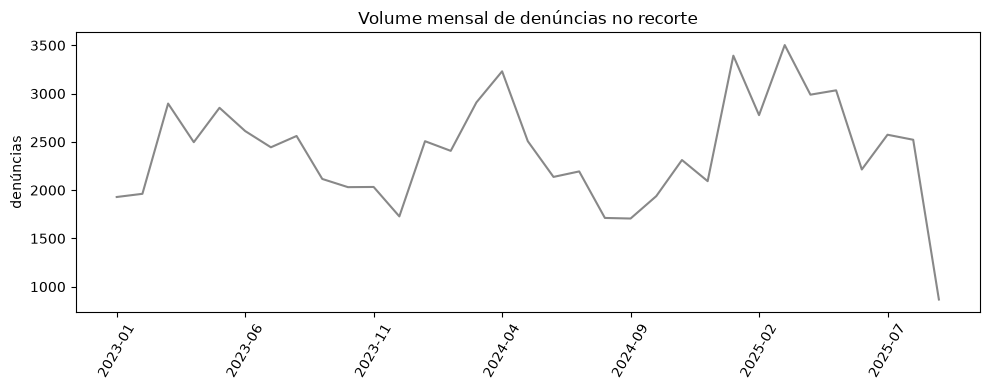

In [17]:
# ===== ESTATÍSTICAS DESCRITIVAS =====
df['MES'] = df['DATA_DEMANDA'].dt.to_period('M').astype(str)
mensal = df.groupby('MES').size()
mensal.to_csv(f'{SAIDAS}/estat_volume_mensal.csv')
df.groupby([df['DATA_DEMANDA'].dt.year, df['DATA_DEMANDA'].dt.month]).size().unstack(0) \
  .to_csv(f'{SAIDAS}/estat_mes_x_ano.csv')
if 'BAIRRO' in df.columns:
    df['BAIRRO'].value_counts().head(20).to_csv(f'{SAIDAS}/estat_top_bairros.csv')
if 'SERVICO_DESCRICAO' in df.columns:
    df['SERVICO_DESCRICAO'].value_counts().head(20).to_csv(f'{SAIDAS}/estat_top_servicos.csv')

print(f'Volume total: {len(df):,} | com coordenada válida: {df["COORD_VALIDA"].mean() * 100:.1f}%')
print('\nVolume por ano:\n', df.groupby('ANO_ARQUIVO').size())
print('\nTop 10 bairros:\n', df['BAIRRO'].value_counts().head(10))

fig, ax = plt.subplots(figsize=(10, 4))
mensal.plot(ax=ax, color='#888')
ax.set_title('Volume mensal de denúncias no recorte')
ax.set_xlabel('')
ax.set_ylabel('denúncias')
plt.xticks(rotation=60)
plt.tight_layout()
fig.savefig(f'{SAIDAS}/volume_mensal.png', dpi=120)
plt.show()

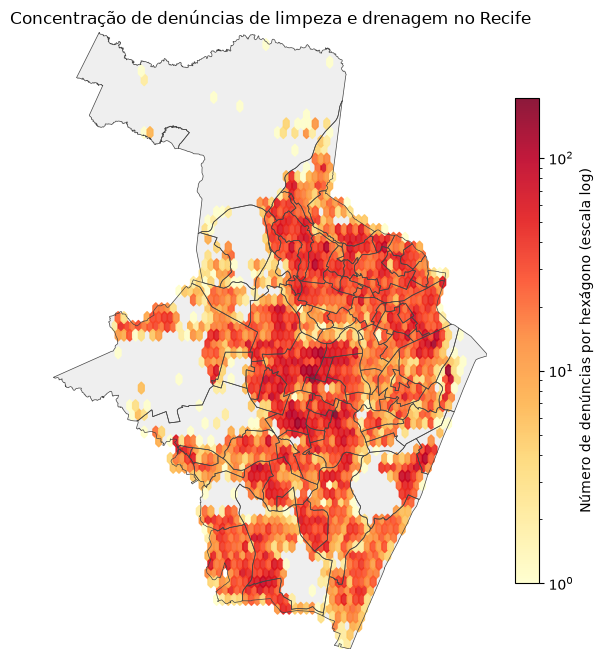

In [18]:
# ===== MAPA DE CONCENTRAÇÃO (hexágonos sobre o contorno dos bairros) =====
vv = df[df['COORD_VALIDA']]
fig, ax = plt.subplots(figsize=(7, 9))
bairros.plot(ax=ax, color='#efefef', edgecolor='none', zorder=1)                  # fundo
hb = ax.hexbin(vv['LON'], vv['LAT'], gridsize=60, bins='log', cmap='YlOrRd',
               mincnt=1, alpha=0.9, zorder=2)                                      # hexágonos
bairros.plot(ax=ax, facecolor='none', edgecolor='#444444', linewidth=0.5, zorder=3)  # contorno POR CIMA
fig.colorbar(hb, ax=ax, shrink=0.7, label='Número de denúncias por hexágono (escala log)')
minx, miny, maxx, maxy = bairros.total_bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Concentração de denúncias de limpeza e drenagem no Recife')
fig.savefig(f'{SAIDAS}/mapa_densidade.png', dpi=150, bbox_inches='tight')
plt.show()

# Fechamento: salvar as bases tratadas e a tabela de perdas

In [19]:
# ===== SALVAR =====
tabela_perdas = pd.DataFrame(perdas)
display(tabela_perdas)

df.to_parquet(f'{PROC}/156_limpo.parquet', index=False)
setores.to_parquet(f'{PROC}/setores_coleta.parquet')
elementos.to_parquet(f'{PROC}/drenagem_elementos.parquet')
rede.to_parquet(f'{PROC}/drenagem_rede.parquet')
descarte.to_csv(f'{PROC}/descarte_filtrado.csv', index=False)
tabela_perdas.to_csv(f'{SAIDAS}/tabela_perdas.csv', index=False)

print('Arquivos em dados/processado:', sorted(os.listdir(PROC)))
print('Arquivos em saidas:', sorted(os.listdir(SAIDAS)))

,etapa,entrou,saiu,perdeu,obs
0,0 juntar 2023-2025,288603,288603,0,
1,1 filtrar recorte,288603,91140,197463,"termos=['LIMPEZA URBANA', 'DRENAGEM']"
2,2 duplicatas exatas,91140,91140,0,
3,3 datas inválidas ou fora do ano,91140,79189,11951,
4,4 classificar SITUACAO,79189,79189,0,"79,189 linhas ainda sem classificação (FINAL/A..."
5,5 validar coordenadas (limite do Recife),41528,41186,342,"fora do limite: linhas mantidas, marcadas COOR..."
6,6 coordenadas faltantes,79189,41528,37661,sem coordenada: mantidas para contagens por ba...
7,7 padronizar texto,79189,79189,0,"BAIRRO, LOGRADOURO e NUMERO"
8,8 projetar para EPSG:31985,79189,79189,0,"denúncias, 75,911 elementos, 73,538 trechos, 9..."
9,9 simplificar setores de coleta,2465,685,1780,partes < 500 m² removidas


Arquivos em dados/processado: ['156_limpo.parquet', 'defesa_civil_limpo.parquet', 'descarte_filtrado.csv', 'drenagem_elementos.parquet', 'drenagem_rede.parquet', 'setores_coleta.parquet']
Arquivos em saidas: ['estat_mes_x_ano.csv', 'estat_top_bairros.csv', 'estat_top_servicos.csv', 'estat_volume_mensal.csv', 'grupos_servico.csv', 'mapa_densidade.png', 'situacoes_unicas.csv', 'tabela_perdas.csv', 'tipos_drenagem.csv', 'volume_mensal.png']


## Próximo passo (Sprint 3)

Agrupar as denúncias com `COORD_VALIDA == True` em pontos (DBSCAN, raio de 80 m, mínimo de 2 denúncias, usando as colunas `X` e `Y` em metros), a partir de `dados/processado/156_limpo.parquet`.